# Selección de crisis y tramos de señal

> 📍 **Dónde estamos: Fase 2 · notebook 1 de 4.** La Fase 1 (exploración) está terminada. Este es el **primer paso de la Fase 2**: lo que decide aquí lo usan todos los notebooks siguientes.

| Fase | | Estado |
|---|---|---|
| 1 | Exploración de datos | ✅ terminada |
| **2** | **Preprocesado y ventanas** | 👉 **en curso: este notebook** |
| 3 | Modelo de predicción (preictal frente a interictal) | pendiente |
| 4 | Clasificación de tipos de crisis | pendiente |
| 5 | Explicabilidad (XAI) | pendiente |
| 6 | Memoria | pendiente |
| 7 | Revisión y defensa | pendiente |

## Qué hace este notebook

Decide **con qué trozos de qué EDF** se va a trabajar en el resto del TFM, antes de tocar la señal:

- **Preictal** (Fase 3, predicción): el tramo sin crisis que hay antes de cada crisis.
- **Interictal** (Fase 3, predicción): señal "normal", lejos de cualquier crisis.
- **Ictal** (Fase 4, clasificación): la propia crisis, con su tipo.

Además cuenta cuántas crisis y pacientes quedan con cada **umbral de lead-in** (los de `umbrales.py`), por tipo, por grupo y por partición.

No lee ningún EDF: trabaja con `edfs.csv` y `crisis.csv` del inventario, así que tarda segundos. **Requisito**: haber ejecutado `fase_01/01_inventario_tusz.ipynb`.

## Los notebooks de la Fase 2

| | Notebook | Qué hace | Entrada → salida | Estado |
|---|---|---|---|---|
| 👉 | `01_seleccion_crisis` | **Elige qué señal se usa.** Para cada crisis decide si sirve para predicción (lead-in útil ≥ umbral) y apunta los tramos preictal, interictal e ictal, con su fichero, inicio y fin. Aplica los márgenes de `umbrales.py` y comprueba que ningún tramo se mete donde no debe. No toca la señal. | Inventario de la Fase 1 → `tramos.csv` | **este notebook** |
| | `02_preprocesado` | **Deja la señal en un formato común.** Lee solo los trozos de `tramos.csv`, construye el montaje bipolar TCP de 22 canales (así da igual la referencia original), remuestrea a 256 Hz y filtra (0,5–40 Hz y notch de 60 Hz), como se decidió en el EDA. | EDF + `tramos.csv` → señal preprocesada | próximamente |
| | `03_ventanas` | **Corta la señal en ventanas** de pocos segundos (tamaño por decidir) y les pone su etiqueta: preictal, interictal o ictal. De cada tramo preictal recorta lo que necesite cada modelo (general o de grupo). | Señal preprocesada → ventanas etiquetadas | próximamente |
| | `04_particiones_y_balanceo` | **Prepara los datos para entrenar.** Mantiene el reparto por paciente de TUSZ (train / dev / eval, sin pacientes compartidos) y equilibra las clases solo en train, porque hay unas 18 h de interictal por cada hora de preictal. Dev y eval se quedan con la proporción real. | Ventanas → conjuntos listos para la Fase 3 | próximamente |

## 1. Importación de librerías

Solo `pandas`, `numpy` y `matplotlib`: no se lee señal. Las utilidades comunes vienen de `tfm_comun/`, cada una de su módulo. La primera línea activa la **recarga automática**: si cambia un módulo de `tfm_comun`, se vuelve a cargar solo, sin reiniciar el kernel. Al final se muestran las versiones de Python y de las librerías (`tfm_comun/versiones.py`), que se guardan también en `configuracion.json`.

In [76]:
# Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# tfm_comun está en ALMA, por encima de la carpeta de la fase: lo añadimos al path de Python
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
# Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado), sin reiniciar el kernel
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

import json
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown

from tfm_comun.rutas import RUTA_OUTPUTS_FASE_01, RUTA_OUTPUTS_FASE_02
from tfm_comun.particiones import SPLITS
from tfm_comun.iconos import con_icono, tabla_con_iconos
from tfm_comun.colores import COLORES_SPLIT, COLORES_PERIODO, COLORES_ETIQUETA, COLOR_DESTACADO
from tfm_comun.numeros import numero_legible
from tfm_comun.ejes import eje_log_legible
from tfm_comun.tipos_crisis import grupo, GRUPOS
from tfm_comun.umbrales import (margen_postictal_s, umbral_leadin_s, sph_s, UMBRAL_LEADIN_POR_DEFECTO_S,
                                SPH_POR_DEFECTO_S, MARGEN_POSTICTAL_POR_DEFECTO_S, UMBRALES_LEADIN_COMPARACION_MIN, DURACION_MINIMA_CRISIS_S)
from tfm_comun.tablas import con_separadores, columnas_planas, mostrar_destacado
from tfm_comun.esquemas import dibujar_esquema_periodos
from tfm_comun.versiones import mostrar_versiones

versiones_usadas = mostrar_versiones(np, pd, matplotlib)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2


## Conceptos clave

Alrededor de cada crisis distinguimos estos periodos (figura de abajo; entre paréntesis, el nombre que se usará en la memoria):

- **Interictal**: señal "normal", lejos de cualquier crisis. Es la clase **"no se acerca ninguna crisis"**.
- **Preictal** (*SOP, seizure occurrence period*): el tramo antes de la crisis. Es la clase **"se acerca una crisis"**.
- **SPH** (*seizure prediction horizon*): el último tramo antes de la crisis, que **no se usa**, para no predecir con actividad que ya es de la crisis. Es la **antelación mínima del aviso**: el tiempo para reaccionar.
- **Margen postictal**: después de una crisis el EEG puede seguir alterado, así que ese tramo **no se usa** ni como preictal ni como interictal. Depende del **tipo de la crisis que acaba**.
- **Lead-in** (*intervalo libre previo*): tiempo sin crisis antes de una crisis, dentro de su fichero. Lo calculó el inventario.
- **Lead-in útil**: el lead-in menos el margen postictal de la crisis anterior. Una crisis se usa en predicción si su lead-in útil llega al **umbral** (= preictal + SPH). En la primera crisis del fichero no hay margen.
- **Ictal**: la crisis en sí. Es lo que usará la clasificación de tipos (Fase 4).

Los valores están en `tfm_comun/umbrales.py`, **en segundos**, para que todo el TFM use los mismos:

| | Umbral | SPH | Preictal | Margen postictal |
|---|---|---|---|---|
| **Por defecto** (modelo general, focales y generalizadas) | 4 min | 1 min | 3 min | 5 min |
| 🟩 **Ausencias** (cortas, muy seguidas y casi sin postictal) | 60 s | 10 s | 50 s | 0 s |

Además, para comparar, se prueban los umbrales de `umbrales.py` (`UMBRALES_LEADIN_COMPARACION_MIN`) con el modelo general; la sección 4.3 analiza cuál conviene.

**Modelos de predicción (Fase 3)**: el principal es un **modelo general**, con todas las crisis y los valores por defecto. Después, como experimentos, **un modelo por grupo de inicio** (ILAE), cada crisis con los valores de su tipo: ♦️ **focal** (`fnsz`, `cpsz`, `spsz`), 🔷 **generalizada** (`gnsz`, `tcsz`, `tnsz`) y 🔹 **ausencia** (`absz`, aparte por sus valores y su señal). No hay un modelo por tipo: casi ningún tipo tiene pacientes suficientes por sí solo.

**Iconos** (los mismos en todo el TFM, definidos en `tfm_comun/iconos.py`). Cada tipo de crisis lleva detrás, entre paréntesis, el icono de su **grupo de inicio**:

| Etiquetas | | Grupos de inicio | | Particiones | |
|---|---|---|---|---|---|
| ⬜ `bckg` fondo | 🟩 `absz` (🔹) ausencia | ♦️ `focal` | empieza en una zona | 🔵 `train` | entrenamiento |
| ⬛ `seiz` / `sin_tipo` crisis sin tipo | 🟪 `tcsz` (🔷) tónico-clónica | 🔷 `generalizada` | empieza en todo el cerebro | 🟡 `dev` | validación |
| 🟥 `fnsz` (♦️) focal no específica | 🟨 `tnsz` (🔷) tónica | 🔹 `ausencia` | generalizada, pero va aparte | 🟢 `eval` | test final |
| 🟦 `gnsz` (🔷) generalizada no específica | 🟫 `spsz` (♦️) parcial simple | | | ⚪ todas | dataset completo |
| 🟧 `cpsz` (♦️) parcial compleja | 🔳 `mysz` (🔷) mioclónica | | | 🔴 | avisos |

En las figuras se usan colores en vez de iconos (matplotlib no dibuja bien los emojis): los periodos usan los de `COLORES_PERIODO` (`tfm_comun/colores.py`).

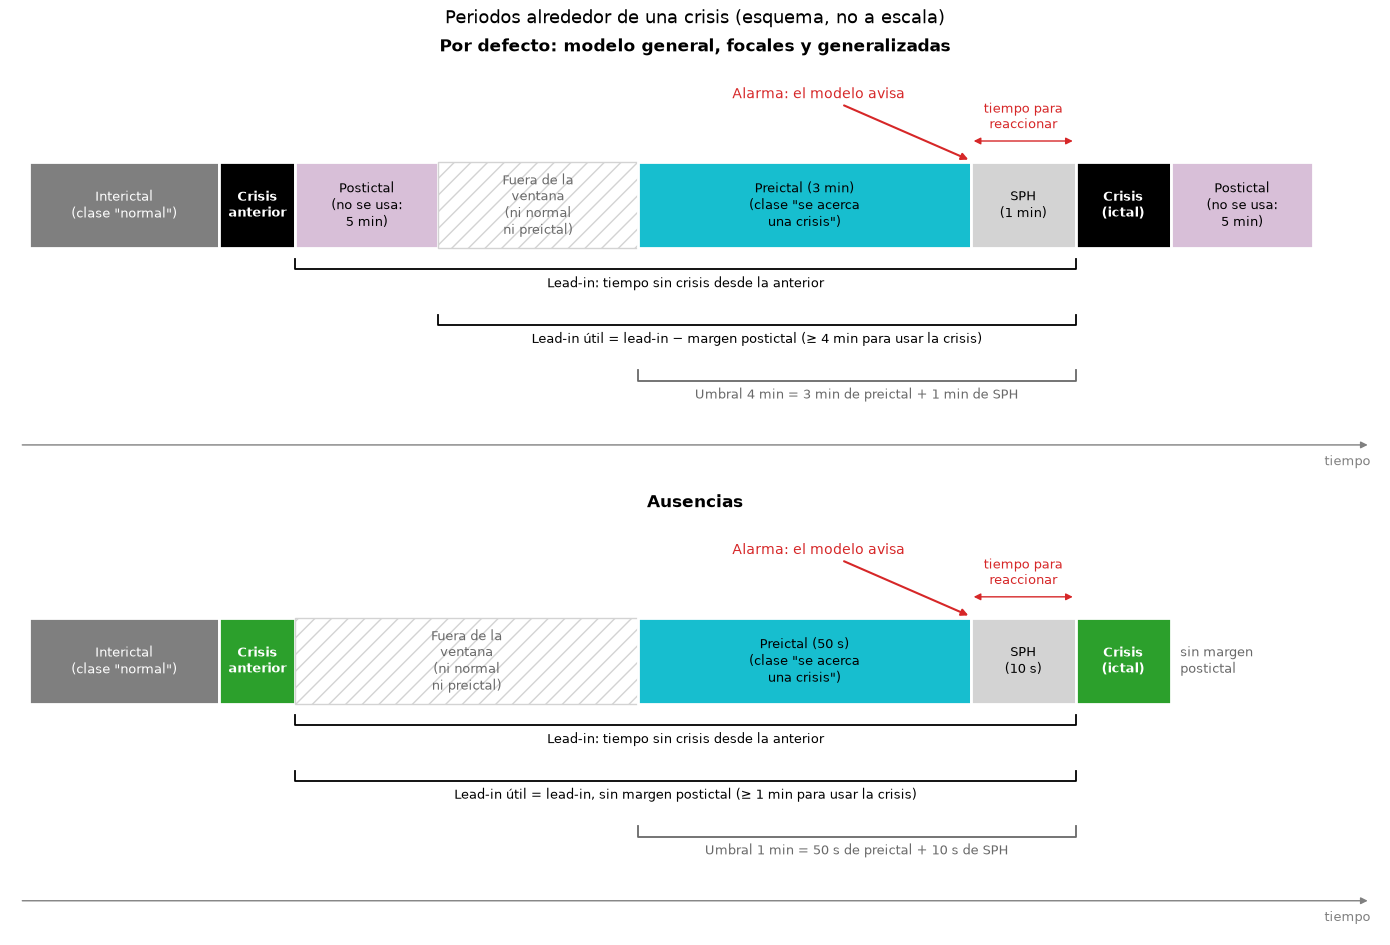

In [77]:
# Esquema de los periodos con los valores por defecto y con los de las ausencias (tfm_comun/umbrales.py)
fig, axes = plt.subplots(2, 1, figsize=(14, 9.6))
for ax, (titulo, tipo, color) in zip(axes, [
        ('Por defecto: modelo general, focales y generalizadas', None, COLORES_PERIODO['ictal']),
        ('Ausencias', 'absz', COLORES_ETIQUETA['absz'])]):
    dibujar_esquema_periodos(ax, umbral_leadin_s(tipo), sph_s(tipo), margen_postictal_s(tipo), color)
    ax.set_title(titulo, fontweight='bold')
fig.suptitle('Periodos alrededor de una crisis (esquema, no a escala)', fontsize=13)
fig.tight_layout()
plt.show()

## 2. Configuración

Todos los parámetros de la selección están aquí. Si se cambia uno, basta con volver a ejecutar el notebook.

| Parámetro | Valor | Qué controla |
|---|---|---|
| `UMBRALES_LEADIN_MIN` | los de `umbrales.py` | Umbrales de lead-in que se comparan en la Fase 3 (de `umbrales.py`) |
| `UMBRAL_PRINCIPAL_MIN` | 4 | Umbral del **modelo general**: valor por defecto de `umbrales.py`, elegido con el análisis de la sección 4.3 |
| `SPH_MIN` | 1 | SPH del **modelo general** (valor por defecto de `umbrales.py`) |
| `DURACION_MINIMA_TRAMO_S` | 60 | Tramos más cortos se descartan (no dan para varias ventanas) |
| `INTERICTAL_SOLO_PACIENTES_CON_CRISIS` | `True` | El interictal sale solo de pacientes que tienen crisis (ver sección 6) |
| `FICHERO_EJEMPLO` | `aaaaacrb_s001_t001` | Fichero que se dibuja en la sección 10: la 🟩 ausencia de ejemplo de la Fase 1 |

Los **umbrales** (de comparación y de cada tipo: lead-in, SPH y margen postictal) y la **duración mínima de una crisis** (2 s) no se fijan aquí: vienen de `tfm_comun/umbrales.py`, en segundos. El **grupo** de cada tipo viene de `tfm_comun/tipos_crisis.py`. La tabla que sale al ejecutar la celda muestra los valores que se van a usar.

La configuración se guarda en `configuracion.json`.

In [78]:
# Rutas
RUTA_INVENTARIO = RUTA_OUTPUTS_FASE_01 / '01_inventario'
RUTA_RESULTADOS = RUTA_OUTPUTS_FASE_02 / '01_seleccion'
RUTA_FIGURAS = RUTA_RESULTADOS / 'figuras'
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)

# Parámetros de la selección
UMBRALES_LEADIN_MIN = UMBRALES_LEADIN_COMPARACION_MIN   # de tfm_comun/umbrales.py
UMBRAL_PRINCIPAL_MIN = UMBRAL_LEADIN_POR_DEFECTO_S // 60   # modelo general; cada tipo tiene el suyo en umbrales.py
SPH_MIN = SPH_POR_DEFECTO_S // 60                         # modelo general; cada tipo tiene el suyo en umbrales.py
DURACION_MINIMA_TRAMO_S = 60
INTERICTAL_SOLO_PACIENTES_CON_CRISIS = True
FICHERO_EJEMPLO = 'aaaaacrb_s001_t001'

assert UMBRAL_PRINCIPAL_MIN in UMBRALES_LEADIN_MIN, 'El umbral principal tiene que estar entre los umbrales.'
assert min(UMBRALES_LEADIN_MIN) > SPH_MIN, 'Cada umbral tiene que dejar sitio para el SPH y algo de preictal.'


# Carga del inventario
for nombre in ['edfs.csv', 'crisis.csv', 'configuracion.json']:
    assert (RUTA_INVENTARIO / nombre).exists(), \
        f'No encuentro {RUTA_INVENTARIO / nombre}. Ejecuta antes fase_01/01_inventario_tusz.ipynb.'

df_ficheros = pd.read_csv(RUTA_INVENTARIO / 'edfs.csv')
df_crisis = pd.read_csv(RUTA_INVENTARIO / 'crisis.csv')
with open(RUTA_INVENTARIO / 'configuracion.json', encoding='utf-8') as f:
    config_inventario = json.load(f)
print(f'Inventario del {config_inventario["fecha"]}: {len(df_ficheros)} ficheros y {len(df_crisis)} crisis')

# Parámetros de cada tipo de crisis (umbrales.py y tipos_crisis.py)
parametros_tipo = pd.DataFrame(
    [{'tipo': t, 'margen postictal (s)': margen_postictal_s(t), 'umbral lead-in (s)': umbral_leadin_s(t),
      'SPH (s)': sph_s(t), 'preictal máx. (s)': umbral_leadin_s(t) - sph_s(t), 'grupo': grupo(t) or '—'}
     for t in sorted(df_crisis.label.unique())]).set_index('tipo')
assert (parametros_tipo['preictal máx. (s)'] > 0).all(), 'El umbral de cada tipo tiene que dejar sitio para su SPH.'
print('Parámetros por tipo (tfm_comun/umbrales.py y tipos_crisis.py)')
display(tabla_con_iconos(parametros_tipo, columnas=['grupo']))

config = {
    'inventario': str(RUTA_INVENTARIO),
    'umbrales_leadin_min': UMBRALES_LEADIN_MIN,
    'umbral_principal_min': UMBRAL_PRINCIPAL_MIN,
    'sph_min': SPH_MIN,
    'parametros_por_tipo': parametros_tipo.to_dict(orient='index'),
    'margen_previo_interictal_min': max(UMBRALES_LEADIN_MIN),
    'duracion_minima_tramo_s': DURACION_MINIMA_TRAMO_S,
    'interictal_solo_pacientes_con_crisis': INTERICTAL_SOLO_PACIENTES_CON_CRISIS,
    'fichero_ejemplo': FICHERO_EJEMPLO,
    'versiones': versiones_usadas,
    'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
with open(RUTA_RESULTADOS / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=4, ensure_ascii=False)

Inventario del 2026-10-27 16:51: 8140 ficheros y 2664 crisis
Parámetros por tipo (tfm_comun/umbrales.py y tipos_crisis.py)


,margen postictal (s),umbral lead-in (s),SPH (s),preictal máx. (s),grupo
tipo,,,,,
🟩 absz (🔹),0,60,10,50,🔹 ausencia
🟧 cpsz (♦️),300,240,60,180,♦️ focal
🟥 fnsz (♦️),300,240,60,180,♦️ focal
🟦 gnsz (🔷),300,240,60,180,🔷 generalizada
🔳 mysz (🔷),300,240,60,180,🔷 generalizada
⬛ sin_tipo,300,240,60,180,—
🟫 spsz (♦️),300,240,60,180,♦️ focal
🟪 tcsz (🔷),300,240,60,180,🔷 generalizada
🟨 tnsz (🔷),300,240,60,180,🔷 generalizada


## 3. Limpieza de crisis

En la Fase 1, el EDA (`fase_01/02_eda_tusz.ipynb`, sección 8.2 *"Otros datos que condicionan las siguientes fases"*) encontró **1 crisis con duración 0 s**: una anotación anómala. Es además la única crisis `sin_tipo`. Se descartan aquí, y se muestra cuáles y por qué, para que no sea un descarte silencioso:

- las crisis **sin tipo** o de **duración 0**: anotaciones anómalas;
- las crisis de **menos de 2 s** (`DURACION_MINIMA_CRISIS_S`, de `umbrales.py`): no llenan ni una ventana de 2 s, la más pequeña que se maneja, así que no sirven para clasificar su tipo en la Fase 4. Solo hay una: una 🟥 `fnsz` (♦️) de 1,98 s, que además no tiene lead-in suficiente para predicción.

Además se calcula el **lead-in útil** de cada crisis: al lead-in se le resta el margen postictal de la crisis anterior del fichero (según el tipo de esa crisis anterior).

Cada crisis recibe además un identificador único (`crisis_id` = fichero + número de crisis dentro del fichero), que acompañará a sus tramos en todas las fases siguientes.

> 🔴 Las crisis descartadas **sí cuentan** para calcular el lead-in y los márgenes: aunque no se usen, la señal de alrededor no es "normal".

In [79]:
df_crisis = df_crisis.sort_values(['file', 'start']).reset_index(drop=True)
df_crisis['crisis_id'] = df_crisis.file + '_c' + df_crisis.groupby('file').cumcount().astype(str).str.zfill(2)
df_crisis['dur_s'] = (df_crisis.stop - df_crisis.start).round(2)
# Fin exacto de la crisis anterior del fichero (0 = inicio del fichero). El leadin_s del inventario está
# redondeado a 0,1 s; para recortar tramos se usa este valor exacto.
df_crisis['fin_anterior_s'] = df_crisis.groupby('file').stop.shift().fillna(0.0)

# Lead-in útil: se descuenta el margen postictal de la crisis anterior (0 si es la primera del fichero)
tipo_anterior = df_crisis.groupby('file').label.shift()
df_crisis['margen_postictal_anterior_s'] = [0.0 if pd.isna(t) else margen_postictal_s(t) for t in tipo_anterior]
df_crisis['inicio_util_s'] = df_crisis.fin_anterior_s + df_crisis.margen_postictal_anterior_s
df_crisis['leadin_util_s'] = (df_crisis.start - df_crisis.inicio_util_s).round(2)

# Montaje y frecuencia de muestreo de cada fichero (los necesita el preprocesado)
info_fichero = df_ficheros.set_index('file')[['montage', 'fs', 'edf_dur_s']]
df_crisis = df_crisis.join(info_fichero, on='file')

# Crisis que se descartan y por qué
df_crisis['motivo_descarte'] = np.select(
    [(df_crisis.dur_s <= 0) | (df_crisis.label == 'sin_tipo'), df_crisis.dur_s < DURACION_MINIMA_CRISIS_S],
    ['anotación anómala (sin tipo o duración 0)', f'dura menos de {DURACION_MINIMA_CRISIS_S} s'], default='')
anomalas = df_crisis.motivo_descarte != ''
print(f'Crisis descartadas: {anomalas.sum()}')
display(tabla_con_iconos(df_crisis[anomalas][['crisis_id', 'split', 'label', 'start', 'stop', 'dur_s', 'motivo_descarte']],
                         columnas=['split', 'label']))
df_validas = df_crisis[~anomalas].copy()
print(f'Crisis válidas: {len(df_validas)} de {len(df_crisis)}')

Crisis descartadas: 2


,crisis_id,split,label,start,stop,dur_s,motivo_descarte
1756,aaaaapks_s016_t000_c00,🔵 train,⬛ sin_tipo,0.0000,0.0000,0.00,anotación anómala (sin tipo o duración 0)
2125,aaaaaqtx_s012_t007_c05,🔵 train,🟥 fnsz (♦️),48.5518,50.5362,1.98,dura menos de 2 s


Crisis válidas: 2662 de 2664


## 4. Recuento por umbral, tipo y partición

Para cada umbral: cuántas crisis superan el **lead-in útil** exigido y de cuántos pacientes, separado por tipo y partición. Es la tabla que decide **qué comparaciones entre umbrales tienen sentido**: el número que manda es el de **pacientes**, sobre todo en 🟢 eval.

Antes, una tabla pequeña con **lo que cuesta el margen postictal**: crisis que superan cada umbral sin descontar el margen y descontándolo.


In [80]:
# Lo que cuesta el margen postictal: crisis que superan cada umbral sin margen y con margen
coste_margen = pd.DataFrame({
    (s, f'≥ {u} min'): [(df_validas[df_validas.split == s].leadin_s >= u * 60).sum(),
                        (df_validas[df_validas.split == s].leadin_util_s >= u * 60).sum()]
    for s in SPLITS for u in UMBRALES_LEADIN_MIN
}, index=['sin margen postictal', 'con margen postictal'])
coste_margen.columns.names = ['split', 'umbral']
print('Crisis que superan cada umbral, sin y con margen postictal')
display(con_separadores(tabla_con_iconos(coste_margen)))

filas = []
for umbral in UMBRALES_LEADIN_MIN:
    validas = df_validas[df_validas.leadin_util_s >= umbral * 60]
    for s in SPLITS:
        d = validas[validas.split == s]
        for tipo, g in d.groupby('label'):
            filas.append({'umbral_min': umbral, 'split': s, 'tipo': tipo,
                          'crisis': len(g), 'pacientes': g.patient.nunique()})
        filas.append({'umbral_min': umbral, 'split': s, 'tipo': 'total',
                      'crisis': len(d), 'pacientes': d.patient.nunique()})
recuento = pd.DataFrame(filas)
recuento.to_csv(RUTA_RESULTADOS / 'crisis_por_umbral_tipo.csv', index=False)

# Tablas para leer: filas = tipo, columnas = partición × umbral
def tabla_recuento(metrica):
    tabla = recuento.pivot_table(index='tipo', columns=['split', 'umbral_min'], values=metrica, fill_value=0)
    tabla = tabla.reindex(columns=pd.MultiIndex.from_product([SPLITS, UMBRALES_LEADIN_MIN]), fill_value=0)
    orden = [t for t in tabla.index if t != 'total'] + ['total']
    tabla = tabla.loc[sorted(orden[:-1], key=lambda t: -tabla.loc[t].sum()) + ['total']].astype(int)
    tabla.columns.names = ['split', 'umbral (min)']
    return tabla

tabla_crisis = tabla_recuento('crisis')
tabla_pacientes = tabla_recuento('pacientes')
print('Crisis que superan cada umbral de lead-in útil')
display(con_separadores(tabla_con_iconos(tabla_crisis)))
print('Pacientes con al menos una crisis que supera cada umbral')
display(con_separadores(tabla_con_iconos(tabla_pacientes)))

Crisis que superan cada umbral, sin y con margen postictal


Crisis que superan cada umbral de lead-in útil


Pacientes con al menos una crisis que supera cada umbral


### 4.1. Mapa del recuento

Cada celda es un tipo de crisis con un umbral: el número grande son las **crisis** y el de abajo, entre paréntesis, los **pacientes**. El color sigue a los pacientes: cuanto más claro, menos pacientes y menos fiable será cualquier resultado de esa celda. El recuadro rojo marca el **umbral de cada tipo** (`umbrales.py`) cuando es uno de los de la comparación; el de las ausencias (60 s) no lo es, y se ve en la sección 4.2. Con muy pocos pacientes (celdas casi blancas), una métrica mide a esos pacientes concretos, no al tipo de crisis.

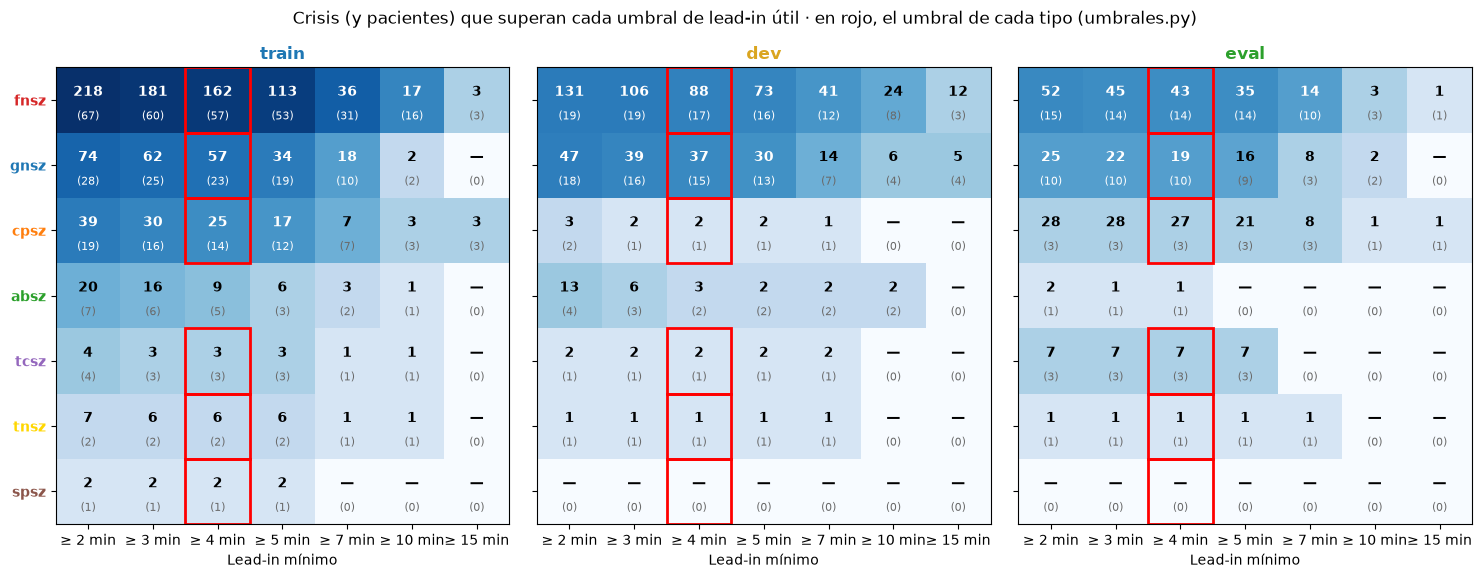

In [81]:
tipos = [t for t in tabla_crisis.index if t != 'total']
fig, axes = plt.subplots(1, len(SPLITS), figsize=(15, 0.55 * len(tipos) + 2), sharey=True)
for ax, s in zip(axes, SPLITS):
    crisis = tabla_crisis.loc[tipos, s].values
    pacientes = tabla_pacientes.loc[tipos, s].values
    ax.imshow(np.log1p(pacientes), cmap='Blues', aspect='auto', vmin=0, vmax=np.log1p(tabla_pacientes.loc[tipos].values.max()))
    for i in range(len(tipos)):
        for j in range(len(UMBRALES_LEADIN_MIN)):
            oscuro = np.log1p(pacientes[i, j]) > 0.55 * np.log1p(tabla_pacientes.loc[tipos].values.max())
            ax.text(j, i - 0.12, numero_legible(crisis[i, j]) if crisis[i, j] else '—', ha='center', va='center',
                    fontsize=10, fontweight='bold', color='white' if oscuro else 'black')
            ax.text(j, i + 0.25, f'({pacientes[i, j]})', ha='center', va='center', fontsize=8,
                    color='white' if oscuro else 'dimgray')
    ax.set_xticks(range(len(UMBRALES_LEADIN_MIN)), [f'≥ {u} min' for u in UMBRALES_LEADIN_MIN])
    ax.set_yticks(range(len(tipos)), tipos)
    for etiqueta in ax.get_yticklabels():
        etiqueta.set_color(COLORES_ETIQUETA.get(etiqueta.get_text(), 'black'))
        etiqueta.set_fontweight('bold')
    ax.set_title(s, color=COLORES_SPLIT[s], fontweight='bold')
    ax.set_xlabel('Lead-in mínimo')
    for i, tipo in enumerate(tipos):
        umbral_tipo = umbral_leadin_s(tipo) / 60
        if umbral_tipo in UMBRALES_LEADIN_MIN:
            j = UMBRALES_LEADIN_MIN.index(umbral_tipo)
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor='red', linewidth=2))
fig.suptitle('Crisis (y pacientes) que superan cada umbral de lead-in útil · en rojo, el umbral de cada tipo (umbrales.py)')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'recuento_umbral_tipo.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.2. Recuento con los parámetros de cada tipo, y por grupo

Cada crisis con el umbral de lead-in, el SPH y el margen postictal **de su tipo** (`umbrales.py`):

- **Por tipo** (`crisis_por_tipo_parametros_propios.csv`): muestra por qué no se hace un modelo por tipo.
- **Por grupo de inicio** (`crisis_por_grupo.csv`): lo que tendrá cada **modelo de grupo** de la Fase 3.

La columna **validación cruzada · pacientes train+dev** es la que cuenta para la **validación cruzada por paciente**, que es como se evaluará un tipo cuando 🟢 eval no tiene pacientes suficientes (caso de las 🟩 ausencias).

In [82]:
def recuento(crisis):
    """Crisis y pacientes de cada partición, y pacientes de train + dev (para la validación cruzada)."""
    fila = {}
    for s in SPLITS:
        d = crisis[crisis.split == s]
        fila[(s, 'crisis')] = len(d)
        fila[(s, 'pacientes')] = d.patient.nunique()
    fila[('validación cruzada', 'pacientes train+dev')] = crisis[crisis.split.isin(['train', 'dev'])].patient.nunique()
    return fila


# Cada crisis con los parámetros de su tipo
validas_tipo = df_validas[df_validas.leadin_util_s >= df_validas.label.map(umbral_leadin_s)]

# Por tipo
recuento_tipo = pd.DataFrame({
    tipo: {('parámetros', 'grupo'): grupo(tipo) or '—', ('parámetros', 'umbral (s)'): umbral_leadin_s(tipo),
           ('parámetros', 'SPH (s)'): sph_s(tipo), ('parámetros', 'margen postictal (s)'): margen_postictal_s(tipo),
           **recuento(validas_tipo[validas_tipo.label == tipo])}
    for tipo in df_validas.label.unique()}).T
recuento_tipo.columns = pd.MultiIndex.from_tuples(recuento_tipo.columns)
recuento_tipo = recuento_tipo.sort_values(('train', 'crisis'), ascending=False)
columnas_planas(recuento_tipo).to_csv(RUTA_RESULTADOS / 'crisis_por_tipo_parametros_propios.csv', index_label='tipo')

# Por grupo de inicio
recuento_grupo = pd.DataFrame({
    nombre_grupo: {('', 'tipos'): ', '.join(sorted(t for t in df_validas.label.unique() if grupo(t) == nombre_grupo)),
                   **recuento(validas_tipo[validas_tipo.label.map(grupo) == nombre_grupo])}
    for nombre_grupo in GRUPOS}).T
recuento_grupo.columns = pd.MultiIndex.from_tuples(recuento_grupo.columns)
columnas_planas(recuento_grupo).to_csv(RUTA_RESULTADOS / 'crisis_por_grupo.csv', index_label='grupo')

# Para mostrar: iconos en filas, columnas y en la columna de grupo
vista_tipo = tabla_con_iconos(recuento_tipo)
vista_tipo[('parámetros', 'grupo')] = vista_tipo[('parámetros', 'grupo')].map(con_icono)
vista_grupo = tabla_con_iconos(recuento_grupo)
print('Por tipo')
display(con_separadores(vista_tipo))
print('Por grupo de inicio')
display(con_separadores(vista_grupo))

Por tipo


Por grupo de inicio


### 4.3. ¿Qué umbral de lead-in conviene? Análisis de crisis, pacientes y señal

Subir el umbral tiene **dos efectos opuestos**:

- cada crisis aporta **más señal preictal** (`umbral − SPH`: 1 min con el umbral de 2, 3 min con el de 4…);
- pero **quedan menos crisis y menos pacientes**.

Para encontrar el equilibrio se miran tres cosas en el **modelo general** (valores por defecto, con el lead-in útil):

1. **Pacientes en dev y eval** → fiabilidad. Con menos de `PACIENTES_MINIMOS` (20), una métrica depende de muy pocas personas.
2. **Crisis en train** → ejemplos distintos para aprender.
3. **Horas de preictal en train** = crisis × (umbral − SPH) → cantidad de señal para entrenar.

**Umbral recomendado**: el que da **más horas de preictal en train** cumpliendo el mínimo de pacientes en dev y en eval. Se prueba una rejilla cada 0,5 min, con un **zoom cada 0,25 min entre 3 y 5 min**, que es donde está el máximo, y se marcan los umbrales de `umbrales.py`. Al final, una tabla con el zoom.

> **Decisión tomada**: el umbral principal es **4 min**. Da casi la misma señal que el máximo (4,25 min) y conserva más pacientes en eval (27 frente a 25), y es un número claro.

> Es una guía para elegir, no una decisión automática: el umbral principal se cambia a mano en `umbrales.py` (`UMBRAL_LEADIN_POR_DEFECTO_S`), y la última palabra la darán los resultados de la Fase 3 con el test común.

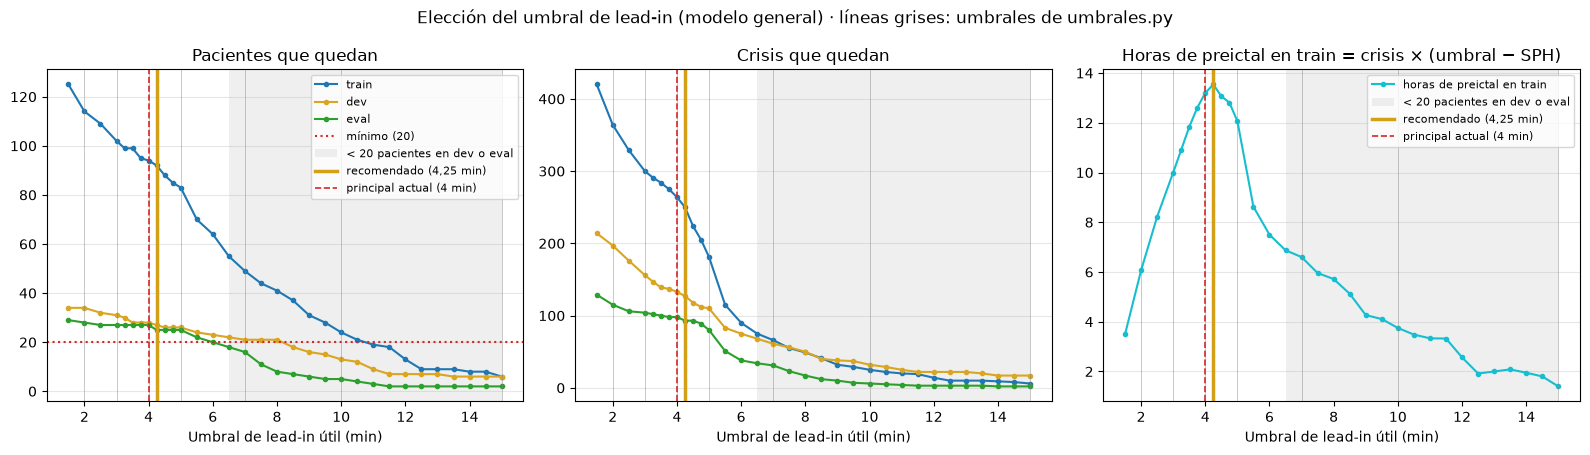

Umbrales de umbrales.py


Zoom entre 3 y 5 min, cada 0,25 min


**Resultado**: con al menos 20 pacientes en dev y en eval, el umbral que más señal preictal da en train es **4,25 min**: 13,5 h, de 250 crisis y 92 pacientes (dev 27, eval 25 pacientes). Entre los umbrales de `umbrales.py`, el mejor es **4 min**. El principal actual (4 min) da 13,2 h, de 264 crisis (dev 28, eval 27 pacientes).

In [83]:
# Parámetros del análisis
PACIENTES_MINIMOS = 20                          # pacientes mínimos en dev y en eval para fiarse de una métrica
REJILLA_MIN = np.arange(1.5, 15.01, 0.5)        # umbrales que se prueban (min); tienen que superar el SPH
REJILLA_FINA_MIN = np.arange(3, 5.001, 0.25)    # zoom donde está el máximo de horas de preictal


def minutos(umbral_min):
    """Umbral escrito con sus decimales: 4.25 -> '4,25', 4.0 -> '4'."""
    return f'{umbral_min:g}'.replace('.', ',')


def analisis_umbral(umbral_min):
    """Crisis y pacientes por partición, y horas de preictal en train, con un umbral (modelo general)."""
    validas = df_validas[df_validas.leadin_util_s >= umbral_min * 60]
    fila = {'umbral_min': umbral_min}
    for s in SPLITS:
        d = validas[validas.split == s]
        fila[f'{s}_crisis'] = len(d)
        fila[f'{s}_pacientes'] = d.patient.nunique()
    fila['horas_preictal_train'] = fila['train_crisis'] * (umbral_min * 60 - SPH_POR_DEFECTO_S) / 3600
    return fila


umbrales_probados = sorted(set(np.round(np.concatenate([REJILLA_MIN, REJILLA_FINA_MIN]), 2)) | set(UMBRALES_LEADIN_MIN))
analisis = pd.DataFrame([analisis_umbral(u) for u in umbrales_probados]).set_index('umbral_min')
analisis['cumple_pacientes'] = ((analisis.dev_pacientes >= PACIENTES_MINIMOS)
                                & (analisis.eval_pacientes >= PACIENTES_MINIMOS))
assert analisis.cumple_pacientes.any(), f'Ningún umbral deja {PACIENTES_MINIMOS} pacientes en dev y eval.'
recomendado = analisis[analisis.cumple_pacientes].horas_preictal_train.idxmax()
recomendado_configurado = analisis.loc[UMBRALES_LEADIN_MIN][analisis.loc[UMBRALES_LEADIN_MIN].cumple_pacientes].horas_preictal_train.idxmax()
analisis.round(2).to_csv(RUTA_RESULTADOS / 'analisis_umbral_leadin.csv')

# Figura: pacientes, crisis y horas de preictal según el umbral
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for s in SPLITS:
    axes[0].plot(analisis.index, analisis[f'{s}_pacientes'], marker='.', color=COLORES_SPLIT[s], label=s)
    axes[1].plot(analisis.index, analisis[f'{s}_crisis'], marker='.', color=COLORES_SPLIT[s], label=s)
axes[0].axhline(PACIENTES_MINIMOS, color='tab:red', linestyle=':', label=f'mínimo ({PACIENTES_MINIMOS})')
axes[2].plot(analisis.index, analisis.horas_preictal_train, marker='.', color=COLORES_PERIODO['preictal'],
             label='horas de preictal en train')
no_cumple = analisis.index[~analisis.cumple_pacientes]
for ax in axes:
    if len(no_cumple):
        ax.axvspan(no_cumple.min(), analisis.index.max(), color='lightgray', alpha=0.35, lw=0,
                   label=f'< {PACIENTES_MINIMOS} pacientes en dev o eval')
    for u in UMBRALES_LEADIN_MIN:
        ax.axvline(u, color='gray', linewidth=0.6, alpha=0.5)
    ax.axvline(recomendado, color=COLOR_DESTACADO, linewidth=2.5, label=f'recomendado ({minutos(recomendado)} min)')
    ax.axvline(UMBRAL_PRINCIPAL_MIN, color='tab:red', linestyle='--', linewidth=1.2,
               label=f'principal actual ({UMBRAL_PRINCIPAL_MIN} min)')
    ax.set_xlabel('Umbral de lead-in útil (min)')
    ax.grid(True, axis='y', alpha=0.3)
axes[0].set_title('Pacientes que quedan')
axes[1].set_title('Crisis que quedan')
axes[2].set_title('Horas de preictal en train = crisis × (umbral − SPH)')
axes[0].legend(fontsize=8)
axes[2].legend(fontsize=8)
fig.suptitle('Elección del umbral de lead-in (modelo general) · líneas grises: umbrales de umbrales.py')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'analisis_umbral_leadin.png', dpi=150, bbox_inches='tight')
plt.show()

def tabla_umbrales(umbrales, mejor, texto_mejor):
    """Tabla para mostrar: crisis y pacientes por partición, horas de preictal en train y si cumple el mínimo."""
    tabla = analisis.loc[umbrales].copy()
    tabla.columns = pd.MultiIndex.from_tuples(
        [tuple(c.split('_', 1)) if c.split('_', 1)[0] in SPLITS else ('', c) for c in tabla.columns])
    tabla[('', 'horas_preictal_train')] = tabla[('', 'horas_preictal_train')].round(2)
    tabla[('', 'cumple_pacientes')] = tabla[('', 'cumple_pacientes')].map({True: '✅', False: '❌'})
    tabla[('', 'nota')] = [texto_mejor if u == mejor else ('principal actual' if u == UMBRAL_PRINCIPAL_MIN else '')
                           for u in tabla.index]
    tabla = tabla.rename(columns={'horas_preictal_train': 'horas preictal train',
                                  'cumple_pacientes': f'≥ {PACIENTES_MINIMOS} pacientes'})
    tabla.index.name = 'umbral (min)'
    return con_separadores(tabla_con_iconos(tabla), decimales=2)


print('Umbrales de umbrales.py')
display(tabla_umbrales(UMBRALES_LEADIN_MIN, recomendado_configurado, '⭐ mejor de umbrales.py'))
print('Zoom entre 3 y 5 min, cada 0,25 min')
display(tabla_umbrales(list(np.round(REJILLA_FINA_MIN, 2)), recomendado, '⭐ recomendado'))

fila = analisis.loc[recomendado]
principal = analisis.loc[UMBRAL_PRINCIPAL_MIN]
display(Markdown(
    f'**Resultado**: con al menos {PACIENTES_MINIMOS} pacientes en dev y en eval, el umbral que más señal preictal da '
    f'en train es **{minutos(recomendado)} min**: {numero_legible(round(fila.horas_preictal_train, 1))} h, de {fila.train_crisis:.0f} crisis '
    f'y {fila.train_pacientes:.0f} pacientes (dev {fila.dev_pacientes:.0f}, eval {fila.eval_pacientes:.0f} pacientes). '
    f'Entre los umbrales de `umbrales.py`, el mejor es **{minutos(recomendado_configurado)} min**. '
    f'El principal actual ({UMBRAL_PRINCIPAL_MIN} min) da {numero_legible(round(principal.horas_preictal_train, 1))} h, de {principal.train_crisis:.0f} '
    f'crisis (dev {principal.dev_pacientes:.0f}, eval {principal.eval_pacientes:.0f} pacientes).'))

## 5. Tramos preictales

El esquema de abajo muestra en **dorado** el tramo que se selecciona en esta sección. Al final, la misma tabla que en la sección 6: **tramos, horas y pacientes** por partición y grupo (las horas son las del tramo más largo, no las de la ventana).

**Qué es un tramo**: un trozo continuo de un EDF, con su inicio y su fin en segundos. Este notebook **no corta ventanas ni lee señal**: solo apunta qué trozos de qué ficheros se usarán después.

**Qué se guarda para cada crisis**: el trozo **más largo** que hay antes de ella y que se puede usar como preictal:

- **empieza** donde acaba el margen postictal de la crisis anterior (o en el segundo 0, si es la primera del fichero);
- **acaba** donde empieza el SPH de su tipo.

**Ejemplo** (🟥 `fnsz` (♦️), valores por defecto): la crisis anterior acaba en el minuto 2 y esta empieza en el 12. El postictal llega hasta el minuto 7, así que el lead-in útil es de 5 min y la crisis entra (umbral de 4 min). El tramo preictal que se guarda va del minuto 7 al 11; el modelo general usará sus 3 últimos minutos (del 8 al 11), y el SPH va del 11 al 12.

**Por qué el tramo más largo y no ya la ventana**: así **una sola tabla sirve para todos los modelos y umbrales**. `03_ventanas` recortará de cada tramo lo que necesite cada modelo:

- el **modelo general**: los 3 min antes del SPH de 1 min, en las crisis con `cumple_4min` (y lo mismo con los otros umbrales para comparar);
- cada **modelo de grupo**: el preictal y el SPH del tipo de la crisis, en las crisis con `cumple_umbral_tipo` (columna `grupo`).

**Qué crisis entran**: las que tienen al menos **2 min** de lead-in útil (el umbral más bajo que se compara), o el umbral de su tipo si es menor (**60 s** en las ausencias).

### Test común entre umbrales

Para comparar umbrales en igualdad, todos los modelos se evalúan además **con las mismas crisis**: las de 🟢 eval con al menos 2 min de lead-in útil, usando solo el minuto que tienen todas (de 2 a 1 min antes de la crisis). Si no, un umbral podría salir mejor solo porque su test es más fácil. Esas crisis llevan `test_comun = True`.

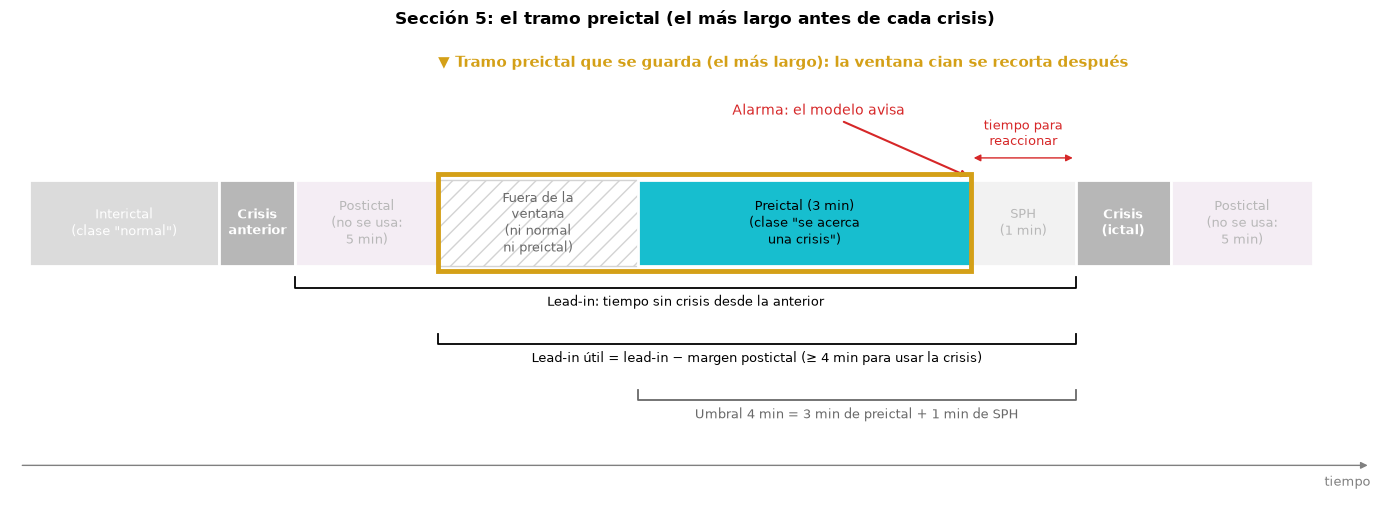

In [84]:
# Qué tramo se selecciona en esta sección (en dorado), con los valores por defecto
fig, ax = plt.subplots(figsize=(14, 5.2))
dibujar_esquema_periodos(ax, UMBRAL_LEADIN_POR_DEFECTO_S, SPH_POR_DEFECTO_S, MARGEN_POSTICTAL_POR_DEFECTO_S,
                         COLORES_PERIODO['ictal'], resaltar='preictal')
ax.set_title('Sección 5: el tramo preictal (el más largo antes de cada crisis)', fontweight='bold')
fig.tight_layout()
plt.show()

In [85]:
def resumen_tramos(tramos_clase, por):
    """Tramos, horas y pacientes de una clase, por partición y por `por` (grupo u origen)."""
    resumen = tramos_clase.assign(horas=(tramos_clase.fin_s - tramos_clase.inicio_s) / 3600).groupby(
        ['split', por]).agg(tramos=('file', 'size'), horas=('horas', 'sum'), pacientes=('patient', 'nunique'))
    resumen['horas'] = resumen.horas.round(1)
    return resumen.reindex(SPLITS, level='split')


umbral_minimo = min(UMBRALES_LEADIN_MIN)
# Entran las crisis que superan el umbral más bajo de la comparación, o el de su tipo si es menor (ausencias: 60 s)
umbral_entrada_s = np.minimum(umbral_minimo * 60, df_validas.label.map(umbral_leadin_s))
d = df_validas[df_validas.leadin_util_s >= umbral_entrada_s]
sph_tipo = d.label.map(sph_s)
preictal = pd.DataFrame({
    'clase': 'preictal', 'split': d.split, 'patient': d.patient, 'session': d.session, 'file': d.file,
    'montage': d.montage, 'fs': d.fs, 'tipo': d.label, 'crisis_id': d.crisis_id,
    'inicio_s': d.inicio_util_s, 'fin_s': d.start - sph_tipo, 'inicio_crisis_s': d.start,
    'leadin_s': d.leadin_s, 'leadin_util_s': d.leadin_util_s, 'origen': 'antes_de_crisis',
})
for umbral in UMBRALES_LEADIN_MIN:
    preictal[f'cumple_{umbral}min'] = preictal.leadin_util_s >= umbral * 60
# Umbral propio de cada tipo (tfm_comun/umbrales.py)
preictal['grupo'] = preictal.tipo.map(grupo)
preictal['umbral_tipo_s'] = preictal.tipo.map(umbral_leadin_s)
preictal['sph_tipo_s'] = sph_tipo
preictal['cumple_umbral_tipo'] = preictal.leadin_util_s >= preictal.umbral_tipo_s
preictal['test_comun'] = (preictal.split == 'eval') & preictal[f'cumple_{umbral_minimo}min']

print(f'Tramos preictales: {len(preictal)} (crisis con lead-in útil ≥ {umbral_minimo} min o ≥ el umbral de su tipo)')
print(f'Test común: {preictal.test_comun.sum()} crisis de {preictal[preictal.test_comun].patient.nunique()} pacientes de 🟢 eval, '
      f'evaluadas en el tramo de {umbral_minimo} a {SPH_MIN} min antes de cada crisis')

resumen_preictal = resumen_tramos(preictal, 'grupo')
display(con_separadores(tabla_con_iconos(resumen_preictal)))

Tramos preictales: 695 (crisis con lead-in útil ≥ 2 min o ≥ el umbral de su tipo)
Test común: 115 crisis de 28 pacientes de 🟢 eval, evaluadas en el tramo de 2 a 1 min antes de cada crisis


## 6. Tramos interictales

El interictal es la clase **"normal"**: señal en la que el modelo tiene que decir "no se acerca ninguna crisis". Por eso tiene que estar **lejos de cualquier crisis**, en las dos direcciones:

- **Antes** de una crisis: a más de **15 min** (el umbral más alto que se compara). Así ningún trozo interictal puede ser preictal con ningún umbral, y el interictal es **el mismo para todos los umbrales**.
- **Después** de una crisis: fuera de su **margen postictal** (5 min; 0 en las ausencias), el mismo que se usa en el preictal.

El esquema de abajo muestra en **dorado** el tramo que se selecciona.

Sale de dos sitios:

1. **Ficheros sin ninguna crisis** (de al menos 1 min): el fichero entero.
2. **Ficheros con crisis**: los trozos que quedan tras quitar, alrededor de cada crisis, los 15 min de antes y el margen postictal de después.

**Ejemplo**: un fichero de 30 min con una 🟥 `fnsz` (♦️) del minuto 20 al 21. Se quita del minuto 5 al 20 (antes) y del 21 al 26 (postictal). Quedan dos tramos interictales: del 0 al 5 y del 26 al 30.

**¿Por qué solo de pacientes con crisis?** Si el preictal saliera solo de pacientes con crisis y el interictal de cualquiera, el modelo podría aprender a **reconocer al paciente** (su forma de EEG, el equipo con el que se grabó…) en vez de a reconocer el estado preictal. Sacando las dos clases de los mismos pacientes, ese atajo desaparece. Se controla con `INTERICTAL_SOLO_PACIENTES_CON_CRISIS`.

> 🔴 Limitación: no se sabe si los tokens de una sesión son seguidos (sección 8 del inventario), así que un fichero sin crisis podría venir justo después de una crisis de otro token. Usar solo sesiones sin ninguna crisis lo evitaría, pero en 🔵 train dejaría el interictal en 50 de los 94 pacientes del umbral principal. Se deja anotado como limitación.

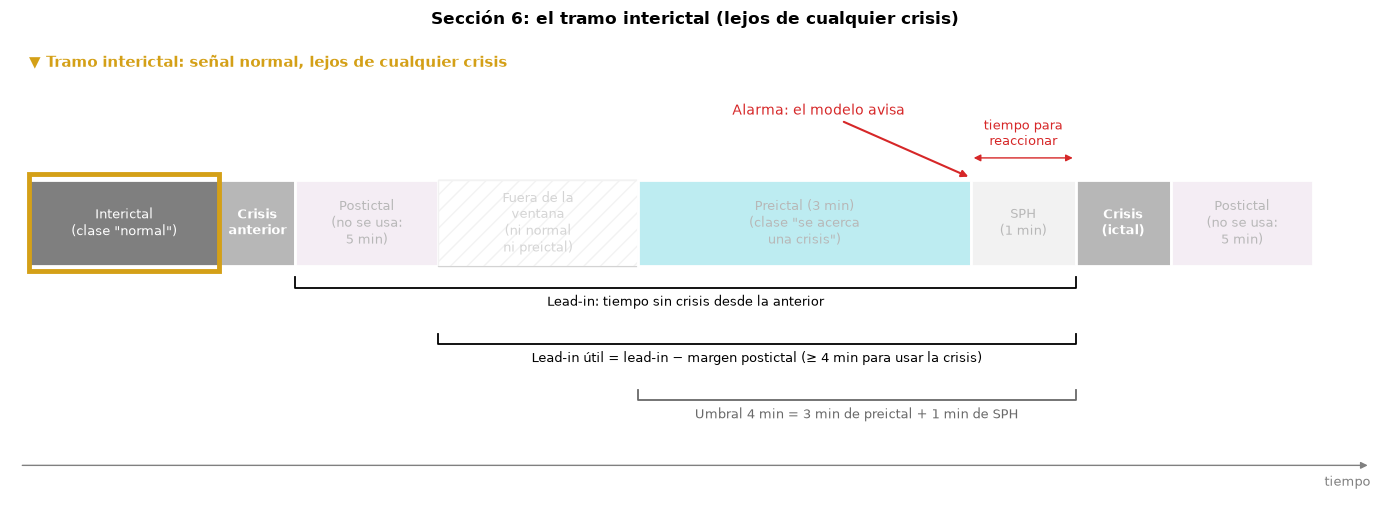

In [86]:
# Qué tramo se selecciona en esta sección (en dorado), con los valores por defecto
fig, ax = plt.subplots(figsize=(14, 5.2))
dibujar_esquema_periodos(ax, UMBRAL_LEADIN_POR_DEFECTO_S, SPH_POR_DEFECTO_S, MARGEN_POSTICTAL_POR_DEFECTO_S,
                         COLORES_PERIODO['ictal'], resaltar='interictal')
ax.set_title('Sección 6: el tramo interictal (lejos de cualquier crisis)', fontweight='bold')
fig.tight_layout()
plt.show()

In [87]:
MARGEN_PREVIO_S = max(UMBRALES_LEADIN_MIN) * 60   # antes de una crisis: fuera del preictal de cualquier umbral
pacientes_con_crisis = set(df_crisis.patient)

def restar_intervalos(inicio, fin, prohibidos):
    """Trozos de [inicio, fin] que no tocan ningún intervalo prohibido. `prohibidos`: lista de (a, b)."""
    libres, cursor = [], inicio
    for a, b in sorted(prohibidos):
        if a > cursor:
            libres.append((cursor, min(a, fin)))
        cursor = max(cursor, b)
        if cursor >= fin:
            break
    if cursor < fin:
        libres.append((cursor, fin))
    return [(a, b) for a, b in libres if b - a > 0]

filas = []
# Fuente 1: ficheros sin ninguna crisis
sin_crisis = df_ficheros[(df_ficheros.n_seiz_events_bi == 0) & (df_ficheros.edf_dur_s >= DURACION_MINIMA_TRAMO_S)]
if INTERICTAL_SOLO_PACIENTES_CON_CRISIS:
    sin_crisis = sin_crisis[sin_crisis.patient.isin(pacientes_con_crisis)]
for f in sin_crisis.itertuples():
    filas.append({'split': f.split, 'patient': f.patient, 'session': f.session, 'file': f.file,
                  'montage': f.montage, 'fs': f.fs, 'inicio_s': 0.0, 'fin_s': f.edf_dur_s,
                  'origen': 'fichero_sin_crisis'})

# Fuente 2: tramos lejos de las crisis dentro de ficheros con crisis (con TODAS las crisis, también las descartadas)
for fichero, cr in df_crisis.groupby('file'):
    f = info_fichero.loc[fichero]
    prohibidos = [(a - MARGEN_PREVIO_S, b + margen_postictal_s(t)) for a, b, t in zip(cr.start, cr.stop, cr.label)]
    for a, b in restar_intervalos(0.0, f.edf_dur_s, prohibidos):
        filas.append({'split': cr.split.iat[0], 'patient': cr.patient.iat[0], 'session': cr.session.iat[0],
                      'file': fichero, 'montage': f.montage, 'fs': f.fs, 'inicio_s': round(a, 2),
                      'fin_s': round(b, 2), 'origen': 'lejos_de_crisis'})

interictal = pd.DataFrame(filas).assign(clase='interictal')
interictal = interictal[interictal.fin_s - interictal.inicio_s >= DURACION_MINIMA_TRAMO_S]

resumen_interictal = resumen_tramos(interictal, 'origen')
display(con_separadores(tabla_con_iconos(resumen_interictal)))

## 7. Tramos ictales

Son **las propias crisis**, de su inicio a su fin, con su tipo y su grupo. Se usan en la **Fase 4 (clasificación de tipos)**: el modelo verá la señal de una crisis y tendrá que decir de qué tipo es.

El esquema de abajo muestra en **dorado** los tramos que se seleccionan. Al final, la misma tabla que en la sección 6: **tramos, horas y pacientes** por partición y grupo.

Aquí entran **todas** las crisis válidas, tengan o no lead-in: para saber el tipo de una crisis no hace falta la señal de antes.

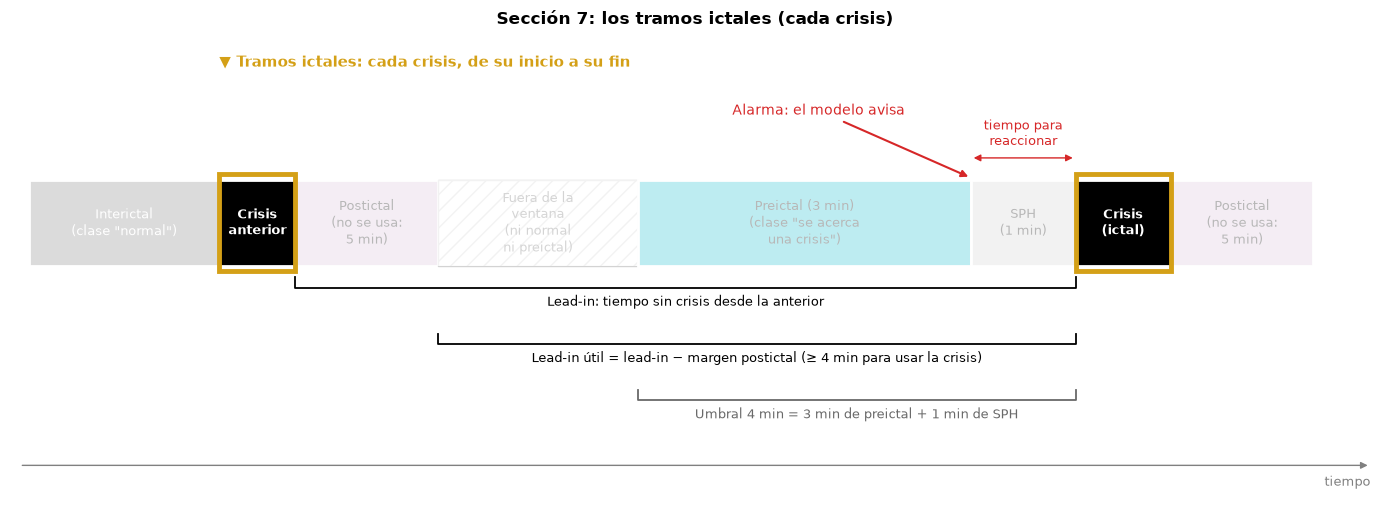

In [88]:
# Qué tramo se selecciona en esta sección (en dorado), con los valores por defecto
fig, ax = plt.subplots(figsize=(14, 5.2))
dibujar_esquema_periodos(ax, UMBRAL_LEADIN_POR_DEFECTO_S, SPH_POR_DEFECTO_S, MARGEN_POSTICTAL_POR_DEFECTO_S,
                         COLORES_PERIODO['ictal'], resaltar='ictal')
ax.set_title('Sección 7: los tramos ictales (cada crisis)', fontweight='bold')
fig.tight_layout()
plt.show()

In [89]:
ictal = pd.DataFrame({
    'clase': 'ictal', 'split': df_validas.split, 'patient': df_validas.patient, 'session': df_validas.session,
    'file': df_validas.file, 'montage': df_validas.montage, 'fs': df_validas.fs, 'tipo': df_validas.label,
    'grupo': df_validas.label.map(grupo), 'crisis_id': df_validas.crisis_id, 'inicio_s': df_validas.start, 'fin_s': df_validas.stop,
    'leadin_s': df_validas.leadin_s, 'origen': 'crisis',
})
print(f'Tramos ictales: {len(ictal)}')
resumen_ictal = resumen_tramos(ictal, 'grupo')
display(con_separadores(tabla_con_iconos(resumen_ictal)))
print('Duración (s): ' + ', '.join(f'p{int(q * 100)}={v:.0f}' for q, v in
                                   (ictal.fin_s - ictal.inicio_s).quantile([0.1, 0.5, 0.9]).items()))

Tramos ictales: 2662


Duración (s): p10=11, p50=35, p90=123


## 8. Tabla única de tramos → `tramos.csv` y comprobaciones

Las tres clases se juntan en una sola tabla: **una fila = un trozo continuo de un EDF**. Es lo único que necesita `02_preprocesado` para saber qué leer.

Antes de guardarla se comprueba que:

1. Todo tramo está **dentro de su fichero** (0 ≤ inicio < fin ≤ duración).
2. **Ningún preictal ni interictal se solapa con una crisis** (contando también las descartadas y el SPH).
3. Ningún interictal está a menos de 15 min **antes** de una crisis ni dentro de su **margen postictal**, así que ninguno se solapa con un preictal.
4. Ningún paciente aparece en dos particiones.
5. Ningún preictal empieza dentro del **margen postictal** de una crisis anterior.

In [90]:
columnas = ['clase', 'split', 'patient', 'session', 'file', 'montage', 'fs', 'tipo', 'grupo', 'crisis_id',
            'inicio_s', 'fin_s', 'duracion_s', 'inicio_crisis_s', 'leadin_s', 'leadin_util_s', 'origen',
            *[f'cumple_{u}min' for u in UMBRALES_LEADIN_MIN], 'umbral_tipo_s', 'sph_tipo_s', 'cumple_umbral_tipo',
            'test_comun']
tramos = pd.concat([preictal, interictal, ictal], ignore_index=True)
tramos['duracion_s'] = (tramos.fin_s - tramos.inicio_s).round(2)
tramos = tramos.reindex(columns=columnas)
for c in [f'cumple_{u}min' for u in UMBRALES_LEADIN_MIN] + ['cumple_umbral_tipo', 'test_comun']:
    tramos[c] = tramos[c].fillna(False).astype(bool)

# 1. Dentro del fichero
duracion = tramos.file.map(info_fichero.edf_dur_s)
fuera = (tramos.inicio_s < 0) | (tramos.fin_s > duracion + 0.01) | (tramos.duracion_s <= 0)
print(f'1. Tramos fuera de su fichero o vacíos (debe ser 0): {fuera.sum()}')

# 2 y 3. Distancia de cada tramo no ictal a la crisis más cercana de su fichero
# (negativa = se solapa; 0 = la toca por el borde, como el preictal que empieza al acabar la crisis anterior)
# (inicio, fin, margen postictal en s) de cada crisis de cada fichero
crisis_por_fichero = {f: list(zip(g.start, g.stop, g.label.map(margen_postictal_s))) for f, g in df_crisis.groupby('file')}
def distancia_a_crisis(t):
    distancias = [max(a - t.fin_s, t.inicio_s - b) for a, b, _ in crisis_por_fichero.get(t.file, [])]
    return min(distancias) if distancias else np.inf
no_ictal = tramos[tramos.clase != 'ictal']
distancia = no_ictal.apply(distancia_a_crisis, axis=1)
solapan = (distancia < -0.01).sum()
print(f'2. Preictales o interictales que se solapan con una crisis (debe ser 0): {solapan}')
def demasiado_cerca(t):
    return any(t.fin_s > a - MARGEN_PREVIO_S + 0.01 and t.inicio_s < b + m - 0.01
               for a, b, m in crisis_por_fichero.get(t.file, []))
cerca = no_ictal[no_ictal.clase == 'interictal'].apply(demasiado_cerca, axis=1).sum()
print(f'3. Interictales dentro de los márgenes de una crisis (debe ser 0): {cerca}')

# 4. Pacientes en una sola partición
particiones_por_paciente = tramos.groupby('patient').split.nunique()
print(f'4. Pacientes en más de una partición (debe ser 0): {(particiones_por_paciente > 1).sum()}')

# 5. Ningún preictal empieza dentro del margen postictal de una crisis anterior
def en_postictal(t):
    return any(b - 0.01 <= t.inicio_s < b + m - 0.01 for a, b, m in crisis_por_fichero.get(t.file, []))
postictal = no_ictal[no_ictal.clase == 'preictal'].apply(en_postictal, axis=1).sum()
print(f'5. Preictales que empiezan dentro de un margen postictal (debe ser 0): {postictal}')

assert fuera.sum() == 0 and solapan == 0 and cerca == 0 and (particiones_por_paciente > 1).sum() == 0 and postictal == 0, \
    '🔴 Alguna comprobación ha fallado: revisa las secciones 5 a 7 antes de seguir.'

tramos.to_csv(RUTA_RESULTADOS / 'tramos.csv', index=False)
print(f'\n{len(tramos)} tramos guardados en tramos.csv')
display(tramos.groupby(['clase', 'split']).size().unstack().reindex(columns=SPLITS).pipe(tabla_con_iconos))

1. Tramos fuera de su fichero o vacíos (debe ser 0): 0
2. Preictales o interictales que se solapan con una crisis (debe ser 0): 0
3. Interictales dentro de los márgenes de una crisis (debe ser 0): 0
4. Pacientes en más de una partición (debe ser 0): 0
5. Preictales que empiezan dentro de un margen postictal (debe ser 0): 0

7665 tramos guardados en tramos.csv


split,🔵 train,🟡 dev,🟢 eval
clase,,,
ictal,1810,492,360
interictal,2274,1485,549
preictal,374,206,115


### 8.1. Qué hay en `tramos.csv`

<div style="background:#fff6d8; color:#1a1a1a; border:2px solid #d4a017; border-radius:8px; padding:10px 14px">
<span style="color:#1a1a1a">🏆 <b style="color:#1a1a1a">El resultado de este notebook.</b> <b style="color:#1a1a1a">tramos.csv</b> es el <b style="color:#1a1a1a">dataset con todo lo que se va a leer de los EDF</b>: qué fichero, desde qué segundo hasta cuál y con qué etiqueta. Es la entrada de <b style="color:#1a1a1a">02_preprocesado</b>. Por eso su salida se muestra en un recuadro dorado.</span>
</div>

Se vuelve a leer el **fichero recién guardado** (no la tabla en memoria), para ver exactamente lo que se ha escrito:

1. Qué significa cada columna, con su tipo de dato y un valor de ejemplo.
2. Unas filas de ejemplo de cada clase (preictal, interictal e ictal).

Las celdas vacías (`—`) son normales: por ejemplo, un tramo interictal no tiene tipo de crisis ni lead-in.

In [91]:
tramos_csv = pd.read_csv(RUTA_RESULTADOS / 'tramos.csv')

# 1. Qué significa cada columna
DESCRIPCION_COLUMNAS = {
    'clase': 'Clase del tramo: preictal, interictal o ictal',
    'split': 'Partición: train, dev o eval',
    'patient': 'Paciente',
    'session': 'Sesión',
    'file': 'Fichero EDF (sin extensión)',
    'montage': 'Montaje original del EDF (se unifica en 02_preprocesado)',
    'fs': 'Frecuencia de muestreo original (Hz)',
    'tipo': 'Tipo de crisis (preictal e ictal)',
    'grupo': 'Grupo de inicio: focal, generalizada o ausencia',
    'crisis_id': 'Crisis a la que pertenece el tramo (preictal e ictal)',
    'inicio_s': 'Inicio del tramo (s desde el inicio del fichero)',
    'fin_s': 'Fin del tramo (s desde el inicio del fichero)',
    'duracion_s': 'Duración del tramo (s)',
    'inicio_crisis_s': 'Inicio de la crisis (preictal): para recortar la ventana con el SPH de cada modelo',
    'leadin_s': 'Lead-in de la crisis, tal cual',
    'leadin_util_s': 'Lead-in descontando el margen postictal de la crisis anterior',
    'origen': 'De dónde sale: antes_de_crisis, crisis, fichero_sin_crisis o lejos_de_crisis',
    **{f'cumple_{u}min': f'La crisis supera el umbral de {u} min (modelo general)' for u in UMBRALES_LEADIN_MIN},
    'umbral_tipo_s': 'Umbral de lead-in del tipo de la crisis (umbrales.py)',
    'sph_tipo_s': 'SPH del tipo de la crisis (umbrales.py)',
    'cumple_umbral_tipo': 'La crisis supera el umbral de su tipo (modelos de grupo)',
    'test_comun': 'La crisis entra en el test común entre umbrales',
}
columnas_csv = pd.DataFrame({
    'tipo de dato': tramos_csv.dtypes.astype(str),
    'ejemplo': [tramos_csv[c].dropna().iloc[0] if tramos_csv[c].notna().any() else '—' for c in tramos_csv.columns],
    'vacías': tramos_csv.isna().sum(),
    'qué es': [DESCRIPCION_COLUMNAS.get(c, '') for c in tramos_csv.columns],
})
columnas_csv.index.name = 'columna'

# 2. Filas de ejemplo de cada clase
FILAS_POR_CLASE = 3
muestra = tramos_csv.groupby('clase', group_keys=False).head(FILAS_POR_CLASE).fillna('—')

mostrar_destacado(
    'tramos.csv: el dataset con todo lo que se leerá de los EDF',
    f'<b>{numero_legible(len(tramos_csv))} filas × {tramos_csv.shape[1]} columnas</b> · una fila = un trozo continuo de un EDF',
    '<b>1. Qué significa cada columna</b>', columnas_csv.style.set_properties(**{'text-align': 'left'}),
    f'<b>2. {FILAS_POR_CLASE} filas de ejemplo de cada clase</b>',
    tabla_con_iconos(muestra.set_index('clase'), columnas=['split', 'tipo', 'grupo']))

,tipo de dato,ejemplo,vacías,qué es
columna,,,,
clase,str,preictal,0,"Clase del tramo: preictal, interictal o ictal"
split,str,train,0,"Partición: train, dev o eval"
patient,str,aaaaaacz,0,Paciente
session,str,s006,0,Sesión
file,str,aaaaaacz_s006_t000,0,Fichero EDF (sin extensión)
montage,str,03_tcp_ar_a,0,Montaje original del EDF (se unifica en 02_preprocesado)
fs,float64,256.0,0,Frecuencia de muestreo original (Hz)
tipo,str,gnsz,4308,Tipo de crisis (preictal e ictal)
grupo,str,generalizada,4308,"Grupo de inicio: focal, generalizada o ausencia"


## 9. Cuánta señal hay de cada clase

Horas de señal de cada clase, por umbral (modelo general) y partición:

- **Preictal**: la ventana que permite cada umbral (`umbral − SPH`: 3 min con el de 4) por cada crisis que lo supera.
- **Interictal**: todo el interictal de **los mismos pacientes** que tienen preictal con ese umbral.

### El desequilibrio de clases

Hay **mucho más interictal que preictal**. La columna **interictal / preictal** dice cuántas horas de señal "normal" hay por cada hora de preictal. Con 4 min, en 🔵 train son unas **18 h por cada hora**: de cada 19 ventanas, 18 son "normal" y solo 1 es "se acerca una crisis".

**Por qué importa**: un modelo que dijera **siempre "normal"** acertaría el 95 % de las veces, pero **no avisaría nunca** de una crisis. Por eso:

- en **🔵 train** se equilibrarán las clases (`04_particiones_y_balanceo`), para que el modelo vea tantos ejemplos de una clase como de la otra;
- en **🟡 dev y 🟢 eval** se deja la proporción real, porque es la que se encontrará en la práctica, y se mide con métricas que no se dejan engañar por ella (sensibilidad, falsas alarmas por hora, AUC-PR), no con el % de aciertos.

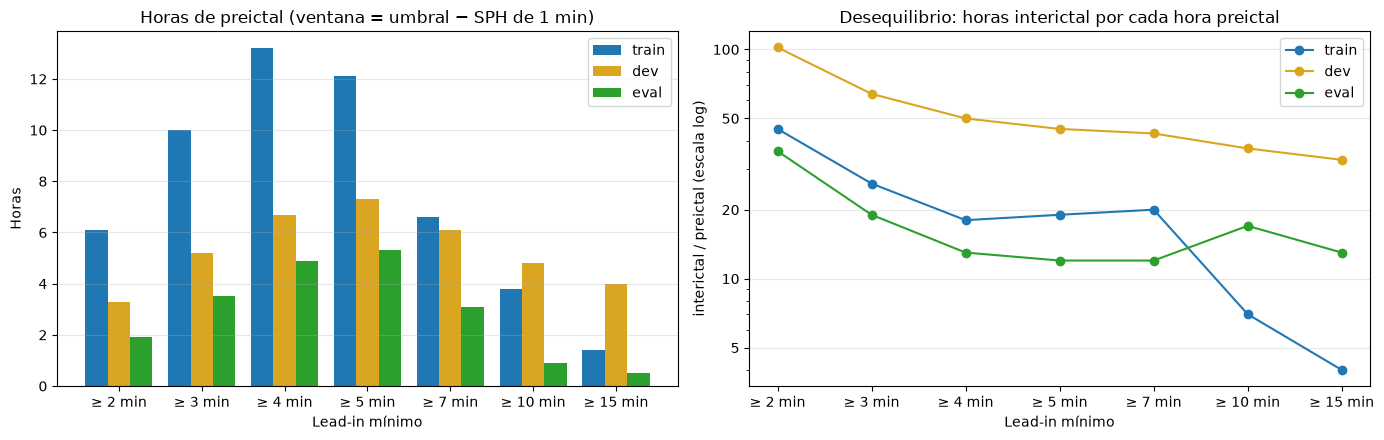

In [92]:
filas = []
for umbral in UMBRALES_LEADIN_MIN:
    pre = tramos[(tramos.clase == 'preictal') & tramos[f'cumple_{umbral}min']]
    for s in SPLITS:
        p = pre[pre.split == s]
        inter = tramos[(tramos.clase == 'interictal') & (tramos.split == s) & tramos.patient.isin(set(p.patient))]
        horas_pre = len(p) * (umbral - SPH_MIN) / 60
        horas_inter = inter.duracion_s.sum() / 3600
        filas.append({'umbral_min': umbral, 'split': s, 'pacientes': p.patient.nunique(), 'crisis': len(p),
                      'horas preictal': round(horas_pre, 1), 'horas interictal': round(horas_inter, 1),
                      'interictal / preictal': round(horas_inter / horas_pre) if horas_pre else np.nan})
horas_clase = pd.DataFrame(filas)
horas_clase.to_csv(RUTA_RESULTADOS / 'horas_por_clase.csv', index=False)
display(con_separadores(tabla_con_iconos(horas_clase.set_index(['umbral_min', 'split']))))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(UMBRALES_LEADIN_MIN))
ancho = 0.27
for k, s in enumerate(SPLITS):
    h = horas_clase[horas_clase.split == s]
    axes[0].bar(x + (k - 1) * ancho, h['horas preictal'], ancho, color=COLORES_SPLIT[s], label=s)
    axes[1].plot(x, h['interictal / preictal'], marker='o', color=COLORES_SPLIT[s], label=s)
axes[0].set_title(f'Horas de preictal (ventana = umbral − SPH de {SPH_MIN} min)')
axes[0].set_ylabel('Horas')
axes[1].set_title('Desequilibrio: horas interictal por cada hora preictal')
axes[1].set_yscale('log')
eje_log_legible(axes[1], 'y')
axes[1].set_ylabel('interictal / preictal (escala log)')
for ax in axes:
    ax.set_xticks(x, [f'≥ {u} min' for u in UMBRALES_LEADIN_MIN])
    ax.set_xlabel('Lead-in mínimo')
    ax.grid(True, axis='y', alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'horas_por_clase.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Un fichero de ejemplo con sus tramos

Para ver de un vistazo qué ha seleccionado el notebook, se dibuja la línea de tiempo de `FICHERO_EJEMPLO` con sus tramos: preictal (con el umbral y el SPH de su tipo, recortado a `umbral − SPH`), margen SPH, crisis, margen postictal e interictal. Lo que queda en blanco es señal que **no se usa** (demasiado cerca de una crisis o dentro de un tramo corto).

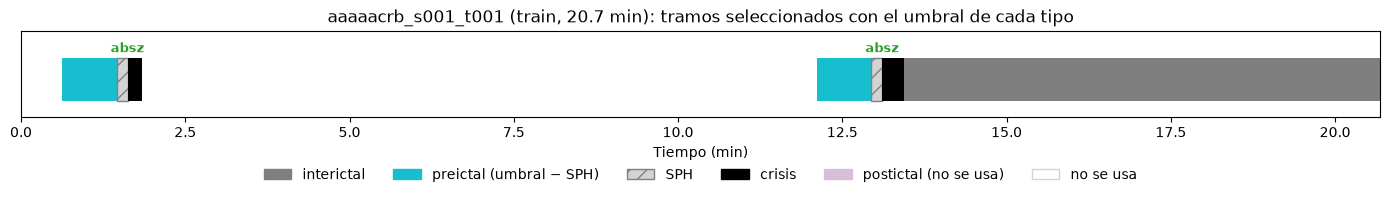

,clase,tipo,inicio_s,fin_s,duracion_s,leadin_s,leadin_util_s,origen
42,preictal,🟩 absz (🔹),0.0000,87.3975,87.40,97.4,97.40,antes_de_crisis
43,preictal,🟩 absz (🔹),110.6762,776.5480,665.87,675.9,675.87,antes_de_crisis
4750,interictal,—,806.3700,1241.0000,434.63,NaN,NaN,lejos_de_crisis
5236,ictal,🟩 absz (🔹),97.3975,110.6762,13.28,97.4,NaN,crisis
5237,ictal,🟩 absz (🔹),786.5480,806.3720,19.82,675.9,NaN,crisis


In [93]:
assert FICHERO_EJEMPLO in info_fichero.index, f'{FICHERO_EJEMPLO} no está en el inventario.'
duracion_ejemplo = info_fichero.loc[FICHERO_EJEMPLO, 'edf_dur_s']
t = tramos[tramos.file == FICHERO_EJEMPLO]
crisis_ejemplo = df_crisis[df_crisis.file == FICHERO_EJEMPLO]

fig, ax = plt.subplots(figsize=(14, 2.6))
def barra(inicio, fin, color, fila=0, **kw):
    ax.broken_barh([(inicio / 60, (fin - inicio) / 60)], (fila - 0.35, 0.7), facecolors=color, **kw)

for r in t[t.clase == 'interictal'].itertuples():
    barra(r.inicio_s, r.fin_s, COLORES_PERIODO['interictal'])
for r in t[(t.clase == 'preictal')].itertuples():
    if r.cumple_umbral_tipo:
        barra(r.inicio_crisis_s - r.umbral_tipo_s, r.fin_s, COLORES_PERIODO['preictal'])
        barra(r.fin_s, r.inicio_crisis_s, COLORES_PERIODO['margen'], hatch='//', edgecolor='gray')
for r in crisis_ejemplo.itertuples():
    if margen_postictal_s(r.label) > 0:
        barra(r.stop, min(r.stop + margen_postictal_s(r.label), duracion_ejemplo), COLORES_PERIODO['postictal'])
    barra(r.start, max(r.stop, r.start + 2), COLORES_PERIODO['ictal'])
    ax.annotate(r.label, (r.start / 60, 0.45), ha='center', fontsize=9,
                color=COLORES_ETIQUETA.get(r.label, 'black'), fontweight='bold')
ax.set_xlim(0, duracion_ejemplo / 60)
ax.set_ylim(-0.6, 0.8)
ax.set_yticks([])
ax.set_xlabel('Tiempo (min)')
split_ejemplo = df_ficheros.set_index('file').loc[FICHERO_EJEMPLO, 'split']
ax.set_title(f'{FICHERO_EJEMPLO} ({split_ejemplo}, {duracion_ejemplo / 60:.1f} min): tramos seleccionados '
             'con el umbral de cada tipo')
ax.legend(handles=[Patch(color=COLORES_PERIODO['interictal'], label='interictal'),
                   Patch(color=COLORES_PERIODO['preictal'], label='preictal (umbral − SPH)'),
                   Patch(facecolor=COLORES_PERIODO['margen'], hatch='//', edgecolor='gray', label='SPH'),
                   Patch(color=COLORES_PERIODO['ictal'], label='crisis'),
                   Patch(color=COLORES_PERIODO['postictal'], label='postictal (no se usa)'),
                   Patch(facecolor='white', edgecolor='lightgray', label='no se usa')],
          loc='upper center', bbox_to_anchor=(0.5, -0.45), ncol=6, frameon=False)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'ejemplo_tramos_fichero.png', dpi=150, bbox_inches='tight')
plt.show()
display(t[['clase', 'tipo', 'inicio_s', 'fin_s', 'duracion_s', 'leadin_s', 'leadin_util_s', 'origen']].fillna({'tipo': '—'}).pipe(tabla_con_iconos, ['tipo']))

## 11. Resumen → `summary.txt`

Reúne los datos y las tablas principales del notebook. Aquí se muestran **una a una**, cada una con su título y con separadores entre particiones; en `summary.txt` se guardan en texto, para consultarlas sin abrir el notebook.

In [94]:
datos = [
    f'Inventario: {config_inventario["fecha"]} · selección: {config["fecha"]}',
    f'Umbrales que se comparan: {UMBRALES_LEADIN_MIN} min · modelo general: {UMBRAL_PRINCIPAL_MIN} min con SPH de {SPH_MIN} min',
    f'Interictal a más de {max(UMBRALES_LEADIN_MIN)} min antes de una crisis · tramo mínimo {DURACION_MINIMA_TRAMO_S} s',
    f'Crisis descartadas: {anomalas.sum()} (anómalas o de menos de {DURACION_MINIMA_CRISIS_S} s)',
    f'Test común: {preictal.test_comun.sum()} crisis de 🟢 eval de {preictal[preictal.test_comun].patient.nunique()} pacientes',
    f'Tramos guardados en tramos.csv: {numero_legible(len(tramos))}',
]
tablas_resumen = {
    'Parámetros por tipo (umbrales.py y tipos_crisis.py)': tabla_con_iconos(parametros_tipo, columnas=['grupo']),
    'Coste del margen postictal: crisis que superan cada umbral': tabla_con_iconos(coste_margen),
    'Crisis que superan cada umbral (lead-in útil)': tabla_con_iconos(tabla_crisis),
    'Pacientes con al menos una crisis que supera cada umbral': tabla_con_iconos(tabla_pacientes),
    'Con los parámetros de cada tipo': vista_tipo,
    'Por grupo de inicio (modelos de grupo de la Fase 3)': vista_grupo,
    'Interictal por fuente': tabla_con_iconos(resumen_interictal),
    'Horas por clase (modelo general)': tabla_con_iconos(horas_clase.set_index(['umbral_min', 'split'])),
    'Tramos por clase y partición': tabla_con_iconos(tramos.groupby(['clase', 'split']).size().unstack().reindex(columns=SPLITS)),
}

# En texto, para summary.txt
texto = ('=== Selección de crisis y tramos (Fase 2 · 01) ===\n' + '\n'.join(datos) + '\n\n'
         + '\n\n'.join(f'--- {titulo} ---\n{tabla.to_string()}' for titulo, tabla in tablas_resumen.items()) + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')

# En el notebook, una tabla detrás de otra
display(Markdown('\n'.join(f'- {d}' for d in datos)))
for titulo, tabla in tablas_resumen.items():
    display(Markdown(f'#### {titulo}'))
    display(con_separadores(tabla))
print(f'Resumen guardado en {RUTA_RESULTADOS / "summary.txt"}')

- Inventario: 2026-10-27 16:51 · selección: 2026-10-27 17:03
- Umbrales que se comparan: [2, 3, 4, 5, 7, 10, 15] min · modelo general: 4 min con SPH de 1 min
- Interictal a más de 15 min antes de una crisis · tramo mínimo 60 s
- Crisis descartadas: 2 (anómalas o de menos de 2 s)
- Test común: 115 crisis de 🟢 eval de 28 pacientes
- Tramos guardados en tramos.csv: 7.665

#### Parámetros por tipo (umbrales.py y tipos_crisis.py)

,margen postictal (s),umbral lead-in (s),SPH (s),preictal máx. (s),grupo
tipo,,,,,
🟩 absz (🔹),0,60,10,50,🔹 ausencia
🟧 cpsz (♦️),300,240,60,180,♦️ focal
🟥 fnsz (♦️),300,240,60,180,♦️ focal
🟦 gnsz (🔷),300,240,60,180,🔷 generalizada
🔳 mysz (🔷),300,240,60,180,🔷 generalizada
⬛ sin_tipo,300,240,60,180,—
🟫 spsz (♦️),300,240,60,180,♦️ focal
🟪 tcsz (🔷),300,240,60,180,🔷 generalizada
🟨 tnsz (🔷),300,240,60,180,🔷 generalizada


#### Coste del margen postictal: crisis que superan cada umbral

#### Crisis que superan cada umbral (lead-in útil)

#### Pacientes con al menos una crisis que supera cada umbral

... (3 outputs left out)

#### Horas por clase (modelo general)

#### Tramos por clase y partición

split,🔵 train,🟡 dev,🟢 eval
clase,,,
ictal,1.810,492,360
interictal,2.274,1.485,549
preictal,374,206,115


Resumen guardado en D:\Dani\TFM IA\03.Codigo\ALMA\outputs\fase_02\01_seleccion\summary.txt


## 12. Conclusiones

**0. El margen postictal cuesta crisis, pero limpia el preictal**
- El margen (`umbrales.py`: 5 min, 0 en las ausencias) se descuenta del lead-in. Con 4 min se pasa de 332 / 194 / 115 crisis a **264 / 133 / 98** (train / dev / eval); con 2 min, de 534 / 278 / 169 a 364 / 197 / 115.
- Las ausencias no pierden ninguna: su margen es 0.
- A cambio, ningún preictal empieza con señal postictal: el modelo no puede aprender "acaba de haber una crisis" en vez de "se acerca una crisis".

**1. El umbral principal pasa a 4 min**
- Con 4 min quedan 264 / 133 / 98 crisis de 94 / 28 / 27 pacientes (🔵 train / 🟡 dev / 🟢 eval).
- Es el que más señal preictal da en train (13,2 h) dejando al menos 20 pacientes en dev y en eval (sección 4.3). Con 5 min serían 181 crisis, 12,1 h y 25 pacientes en eval.
- Con 10 y 15 min, 🟢 eval se queda en **5 y 2 pacientes** y 🔵 train en 25 y 6 crisis: sirven para **comparar de forma orientativa**, no para sacar conclusiones fuertes.
- Para que la comparación sea justa, todos los umbrales se evalúan también en el **test común** (115 crisis de 28 pacientes de eval, en el minuto de 2 a 1 min antes de la crisis).

**2. Modelo general y, como experimentos, un modelo por grupo de inicio** (sección 4.2)
- **Por tipo no da**: solo 🟥 `fnsz` (♦️) y 🟦 `gnsz` (🔷) tienen pacientes suficientes en las tres particiones; el resto se queda en 1–3 pacientes en dev o eval.
- **Por grupo** (cada crisis con los parámetros de su tipo), crisis / pacientes en train · dev · eval:
  - ♦️ **focal**: 189 / 70 · 90 / 18 · 70 / 16.
  - 🔷 **generalizada**: 66 / 28 · 40 / 15 · 27 / 12.
  - 🔹 **ausencia** (`absz`, 60 s de lead-in, 10 s de SPH, sin margen postictal): 30 / 8 · 22 / 4 · 2 / 1. En eval no se puede evaluar: se usará **validación cruzada por paciente en train + dev (12 pacientes)**, con resultado orientativo. Con un aviso de 10 a 50 s, está más cerca de una **detección temprana** que de una predicción.
- El plan: entrenar el **general**, ajustar a partir de él un modelo por grupo (*fine-tuning*) y comparar los dos en las crisis de cada grupo. Así se comprueba con datos si separar mejora.

**3. El interictal sale de los mismos pacientes y no se solapa con ningún preictal**
- Casi todo viene de ficheros sin crisis (371 h en train); los tramos lejos de crisis aportan poco (13,3 h), pero cubren a pacientes que no tienen ficheros sin crisis.
- Antes de una crisis, el interictal empieza a más de 15 min: es **el mismo para todos los umbrales**.

**4. Desequilibrio de clases: hay que balancear**
- Con 4 min hay **18 h de interictal por cada hora de preictal** en train, 50 en dev y 13 en eval.
- El balanceo se hará **solo en train** (`04_particiones_y_balanceo`). Dev y eval mantienen la proporción real, y se evaluará con métricas que no dependan de ella (AUC-PR, sensibilidad, falsas alarmas por hora), no con *accuracy*.

**5. Listo para el preprocesado**
- `tramos.csv` tiene 7.665 tramos que han pasado las cinco comprobaciones de la sección 8. `02_preprocesado` leerá solo esos trozos de EDF.

## 13. Archivos generados y siguiente paso

En `outputs/fase_02/01_seleccion/`:

- `configuracion.json`: parámetros de la selección y fecha.
- `crisis_por_umbral_tipo.csv`: crisis y pacientes por umbral × partición × tipo (formato largo).
- `analisis_umbral_leadin.csv`: crisis, pacientes y horas de preictal con cada umbral (sección 4.3).
- `crisis_por_grupo.csv`: crisis y pacientes por grupo de inicio (focal, generalizada, ausencia).
- `crisis_por_tipo_parametros_propios.csv`: crisis y pacientes por tipo con su umbral, SPH y margen postictal.
- `tramos.csv`: **una fila por tramo** (preictal, interictal o ictal, con su tipo y su grupo) con su fichero, montaje, frecuencia, inicio y fin. Es la entrada de `02_preprocesado`. Qué significa cada columna: sección 8.1.
- `horas_por_clase.csv`: horas de preictal e interictal por umbral y partición.
- `summary.txt`: tablas resumen (con iconos).
- `figuras/`: `recuento_umbral_tipo.png`, `horas_por_clase.png`, `ejemplo_tramos_fichero.png`.

Los CSV se guardan **sin iconos** para que se puedan leer fácilmente desde código.

**Siguiente paso**: `02_preprocesado.ipynb`, que lee solo los EDF de `tramos.csv` y deja la señal en un formato común (montaje TCP, 256 Hz, filtrado).